# What moves the ringgit? An EDA of 20 years of BNM exchange rates

**Question.** How has MYR moved against 8 major and regional currencies since 2006, how volatile
is it, and what (if anything) explains the moves: oil, interest rates, or BNM's own policy rate?

**Data.** Bank Negara Malaysia Open API, 12:00 (noon) middle rate, Jan 2006 to today, for
USD, SGD, CNY, EUR, GBP, JPY, THB, IDR. OPR decisions from the same API. Brent crude and the
US effective Fed funds rate from FRED, used only as context.

**Convention.** Rates are *MYR per 1 unit of foreign currency*. A **rising line = weaker ringgit**.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm

from myr_fx import db, insights as ins

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": 0.3})
DOCS = ROOT / "docs"
DOCS.mkdir(exist_ok=True)

con = db.ensure_db(":memory:", data_dir=ROOT / "data")
w = db.fx_wide(con)
opr = db.opr_frame(con)
macro = db.macro_wide(con)
con.close()
print(f"{w.index.min():%Y-%m-%d} to {w.index.max():%Y-%m-%d}: {len(w):,} business days x {w.shape[1]} currencies")
w.tail(3).round(4)

2006-01-03 to 2026-11-12: 5,132 business days x 8 currencies


currency,CNY,EUR,GBP,IDR,JPY,SGD,THB,USD
date,,,,,,,,
2026-11-10,0.6078,4.5504,5.4511,0.0002,0.0257,3.1718,0.1213,4.0545
2026-11-11,0.6105,4.5484,5.4374,0.0002,0.0256,3.1786,0.1210,4.0745
2026-11-12,0.6124,4.5228,5.4144,0.0002,0.0256,3.1781,0.1209,4.0840


## 0. Data quality

BNM's history is not perfectly clean. The ingest step (`src/myr_fx/validate.py`) removes:

* **Weekend rows** where BNM repeated Friday's quote (about 40 old weekends).
* **Bad prints.** On 1 and 2 Jan 2007 the EUR and GBP rows hold *cross rates* (GBP = 1.80, which is
  GBP/USD) and JPY is scaled 100x too small. On 5 Mar 2007 THB jumps 6.5% and is back the next day.
  The rule: more than 15% away from the 11-day median, or a jump above 4% that returns within 1%
  the next day.

What's left: the largest one-day moves are real events. GE13 (CNY, 6 May 2013), Brexit
(GBP, 24 Jun 2016), COVID (SGD, Mar 2020), the 5 Aug 2024 carry-trade unwind (USD) and the
Oct 2008 rupiah crash (IDR).

In [2]:
r = ins.log_returns(w) * 100
big = pd.DataFrame({"largest |daily move| %": r.abs().max().round(2),
                    "date": r.abs().idxmax().dt.date})
big.sort_values("largest |daily move| %", ascending=False)

,largest |daily move| %,date
currency,,
IDR,17.01,2008-10-28
GBP,7.27,2016-06-24
JPY,6.05,2016-06-24
EUR,3.70,2015-10-23
USD,2.94,2024-08-05
THB,2.70,2006-12-21
CNY,2.56,2013-05-06
SGD,2.26,2020-03-30


## 1. Long-run trend: who did MYR gain or lose against?
Every series is rebased to 100 on the first day. Above 100 means that currency got more expensive in MYR.

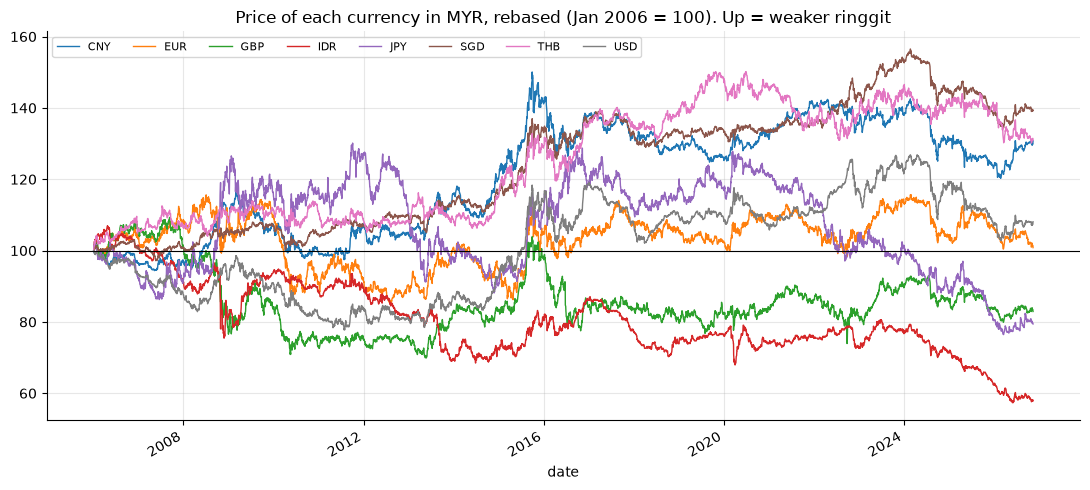

,% change since 2006 (+ = MYR weaker)
currency,
IDR,-42.1
JPY,-20.6
GBP,-17.1
EUR,0.8
USD,8.1
CNY,30.8
THB,31.0
SGD,39.4


In [3]:
rebased = w / w.iloc[0] * 100
ax = rebased.plot(figsize=(11, 5), lw=1)
ax.axhline(100, color="k", lw=0.8)
ax.set_title("Price of each currency in MYR, rebased (Jan 2006 = 100). Up = weaker ringgit")
ax.legend(ncol=8, loc="upper left", fontsize=8)
plt.tight_layout(); plt.savefig(DOCS / "rebased.png", dpi=120); plt.show()

chg = (w.iloc[-1] / w.iloc[0] - 1) * 100
chg.sort_values().round(1).to_frame("% change since 2006 (+ = MYR weaker)")

In [4]:
episodes = {
    "2014-07 to 2016-01: oil crash + 1MDB": ("2014-07-01", "2016-01-20"),
    "2020-01 to 2020-04: COVID shock": ("2020-01-02", "2020-04-01"),
    "2022-01 to 2024-02: Fed hiking cycle": ("2022-01-03", "2024-02-20"),
    "2024-02 to 2024-09: the 2024 rebound": ("2024-02-20", "2024-09-30"),
}
rows = {}
for name, (a, b) in episodes.items():
    s = w.loc[a:b]
    rows[name] = ((s.iloc[-1] / s.iloc[0] - 1) * 100).round(1)
pd.DataFrame(rows).T[["USD", "SGD", "CNY", "EUR", "JPY"]]

currency,USD,SGD,CNY,EUR,JPY
2014-07 to 2016-01: oil crash + 1MDB,36.5,18.3,28.7,9.2,18.4
2020-01 to 2020-04: COVID shock,5.9,0.1,4.1,4.1,6.8
2022-01 to 2024-02: Fed hiking cycle,14.9,15.3,1.5,9.0,-11.9
2024-02 to 2024-09: the 2024 rebound,-14.3,-9.9,-12.0,-11.2,-9.5


**Finding.** Over 20 years MYR is roughly where it started against USD (+8%) and EUR (+1%).
It is much weaker against SGD (+39%), CNY (+31%) and THB (+31%), and stronger against IDR, JPY
and GBP. The damage was concentrated in a few episodes, not spread evenly. The **2014–16
oil-price collapse and 1MDB scandal** added 36% to USD/MYR in 18 months. The **2022–24 Fed
hiking cycle** added another 15%. USD/MYR peaked at **4.79 on 17 Apr 2024**, then gave back 14%
by September 2024.

**Why it matters.** For a Malaysian student or importer, the risk is not a slow drift but a
few sharp regime shifts. Those are exactly the moves a statistical forecast cannot see coming
(section 7).

## 2. Volatility
Annualised standard deviation of daily log returns over a 21-business-day window.

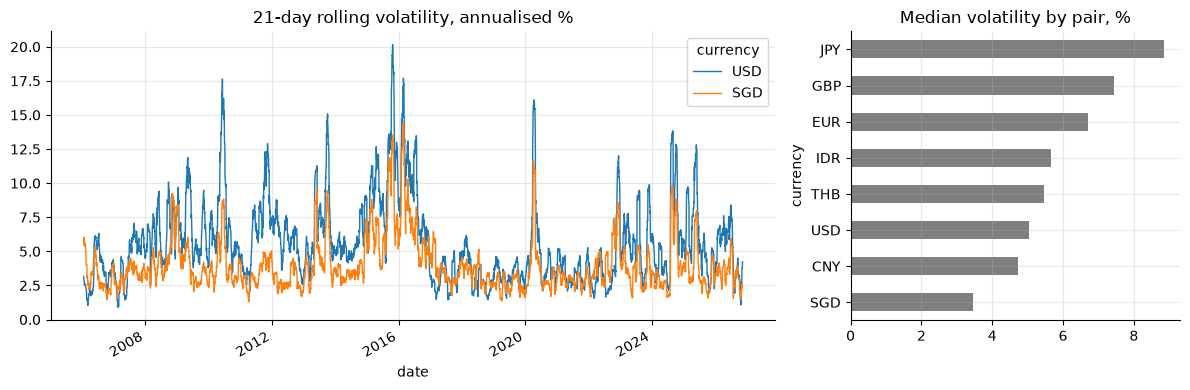

date,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
currency,,,,,,,,,,,,,,,,,,,,,
USD,3.8,4.7,6.8,6.9,8.2,7.3,5.9,7.6,5.9,11.1,...,3.3,3.6,3.4,6.3,3.6,4.9,6.3,7.0,6.4,5.5
SGD,3.3,3.3,5.1,3.8,4.6,3.4,2.8,5.2,3.9,7.7,...,3.7,3.4,2.6,4.6,2.9,4.8,3.8,4.8,3.9,3.5
CNY,3.5,4.6,6.4,6.7,8.1,6.8,5.3,7.5,5.9,10.9,...,3.8,4.1,3.5,5.3,3.3,5.3,5.0,5.6,5.9,4.7
EUR,7.0,6.2,13.1,9.3,10.3,9.1,6.3,8.5,7.2,14.1,...,6.8,6.0,5.0,7.7,5.0,9.1,6.3,6.2,7.1,4.9


In [5]:
vol = ins.rolling_vol(w, 21)
fig, ax = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2.2, 1]})
vol[["USD", "SGD"]].plot(ax=ax[0], lw=1)
ax[0].set_title("21-day rolling volatility, annualised %")
vol.median().sort_values().plot.barh(ax=ax[1], color="tab:gray")
ax[1].set_title("Median volatility by pair, %")
plt.tight_layout(); plt.show()

annual = (ins.log_returns(w).groupby(w.index.year).std() * np.sqrt(252) * 100).round(1)
annual[["USD", "SGD", "CNY", "EUR"]].T

**Finding.** SGD/MYR is the calmest pair (median 3.4% a year). Singapore's basket-managed
currency and its close trade ties with Malaysia keep the two moving together. JPY (8.9%) and
GBP (7.4%) are the most volatile. USD/MYR volatility is regime-dependent: about 3.5% in the quiet
2017–2019 and 2021 years, **11% in 2015**, with a single-window peak of **20% on 23 Oct 2015**.
Volatility clusters: calm and turbulent periods persist. That is why a confidence band built
from one long-run average is too narrow in crises and too wide in calm periods.

## 3. MYR strength index
An equal-weight basket index: the geometric mean of (base-day rate / today's rate) across all 8
currencies, so IDR and GBP count equally despite very different price levels. Above 100 = MYR
stronger than in Jan 2006.

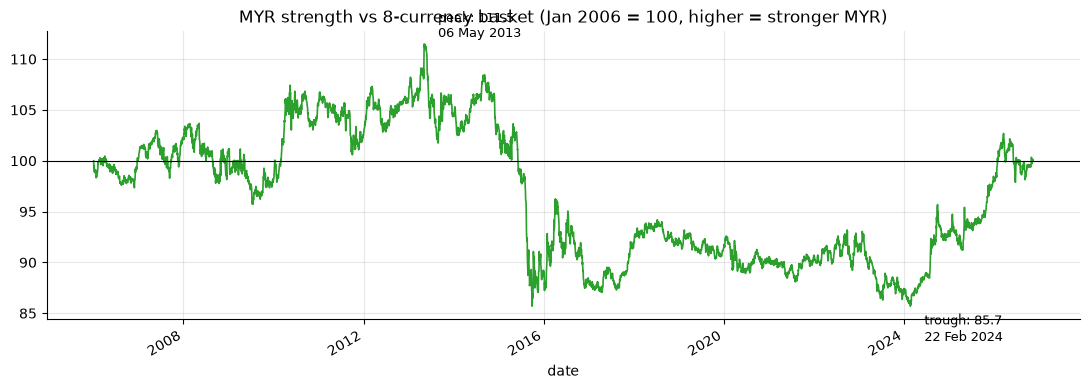

now 100.1


In [6]:
si = ins.strength_index(w)
ax = si.plot(figsize=(11, 4), lw=1.2, color="tab:green")
ax.axhline(100, color="k", lw=0.8)
for d, label in [(si.idxmax(), "peak"), (si.idxmin(), "trough")]:
    ax.annotate(f"{label}: {si[d]:.1f}\n{d:%d %b %Y}", (d, si[d]), textcoords="offset points",
                xytext=(10, -25 if label == "trough" else 5), fontsize=9)
ax.set_title("MYR strength vs 8-currency basket (Jan 2006 = 100, higher = stronger MYR)")
plt.tight_layout(); plt.savefig(DOCS / "strength_index.png", dpi=120); plt.show()
print(f"now {si.iloc[-1]:.1f}")

**Finding.** Against the basket, MYR peaked on **6 May 2013**, the trading day after the 13th
general election (GE13) removed political uncertainty. It bottomed on **22 Feb 2024** (85.7). Today it
is back to about 100, so the 2024–25 recovery undid the whole post-2013 decline in basket terms.
The single-pair USD/MYR view exaggerates how weak the ringgit "is": much of USD/MYR is a
*US dollar* story.

## 4. Which currencies move together?
Correlation of daily log returns, full sample.

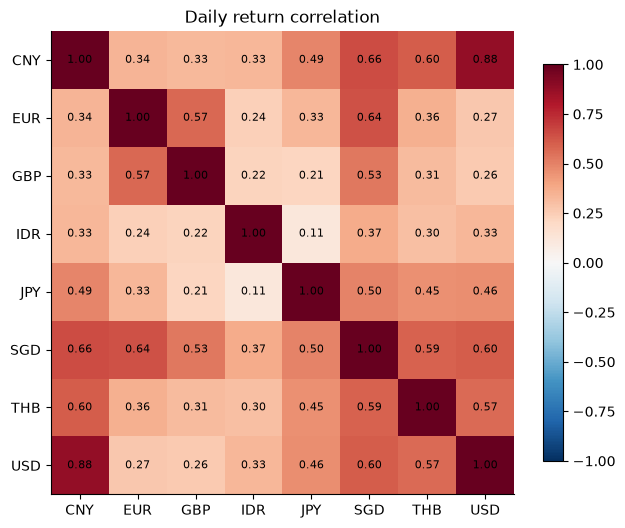

In [7]:
c = ins.log_returns(w).corr()
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(c, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(c)), c.columns); ax.set_yticks(range(len(c)), c.index)
for i in range(len(c)):
    for j in range(len(c)):
        ax.text(j, i, f"{c.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.grid(False); fig.colorbar(im, shrink=0.8); ax.set_title("Daily return correlation")
plt.tight_layout(); plt.show()

**Finding.** USD and CNY returns against MYR are almost the same series (ρ = 0.88), which
reflects China's managed peg to the dollar. SGD sits in the middle of everything (0.5–0.66 with every
pair), as you'd expect from a basket-managed currency. EUR and GBP are their own cluster
(0.57). **Practical implication:** "diversifying" a foreign-currency fee payment across USD and
CNY gives almost no diversification.

*Caveat:* BNM fixes at noon Kuala Lumpur time, before European markets open, so EUR and GBP
correlations are understated by timing mismatch.

## 5. What drives MYR? Oil and the interest-rate gap
Malaysia is a commodity exporter (petroleum, LNG and palm oil), and capital flows chase the
interest-rate gap between the US and Malaysia. We test both with FRED data.

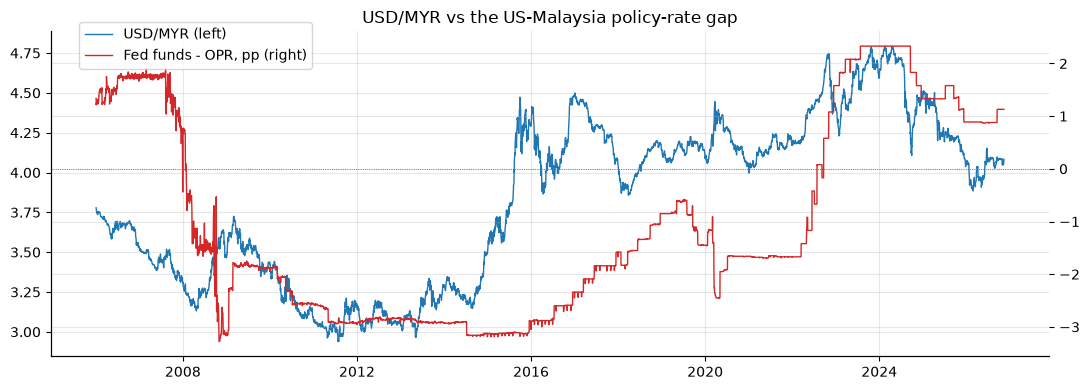

level correlation USD/MYR vs rate gap: 0.49


In [8]:
opr_daily = (opr.set_index("date")["new_opr_level"]
             .reindex(pd.date_range("2005-01-01", w.index.max())).ffill())
d = (pd.DataFrame({"usd": w["USD"]}).join(macro).join(opr_daily.rename("opr"))
     .ffill().dropna())
d["rate_gap"] = d["fed_funds"] - d["opr"]

fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(d.index, d["usd"], color="tab:blue", lw=1, label="USD/MYR (left)")
ax2 = ax.twinx()
ax2.plot(d.index, d["rate_gap"], color="tab:red", lw=1, label="Fed funds - OPR, pp (right)")
ax2.axhline(0, color="tab:red", lw=0.6, ls=":")
ax.set_title("USD/MYR vs the US-Malaysia policy-rate gap")
fig.legend(loc="upper left", bbox_to_anchor=(0.07, 0.95))
plt.tight_layout(); plt.savefig(DOCS / "rate_gap.png", dpi=120); plt.show()
print(f"level correlation USD/MYR vs rate gap: {d['usd'].corr(d['rate_gap']):.2f}")

In [9]:
mo = d.resample("ME").last()
x = pd.DataFrame({
    "usd_chg_%": np.log(mo["usd"]).diff() * 100,
    "brent_chg_%": np.log(mo["brent_usd"]).diff() * 100,
    "rate_gap_chg_pp": mo["rate_gap"].diff(),
}).dropna()
fit = sm.OLS(x["usd_chg_%"], sm.add_constant(x[["brent_chg_%", "rate_gap_chg_pp"]])).fit(
    cov_type="HAC", cov_kwds={"maxlags": 3})
print(fit.summary().tables[1])
print(f"R-squared: {fit.rsquared:.3f}   months: {int(fit.nobs)}")

by_period = {}
for a, b in [("2006", "2013"), ("2014", "2016"), ("2017", "2021"), ("2022", "2026")]:
    s = x.loc[a:b]
    by_period[f"{a}-{b}"] = {"corr(USD/MYR, Brent)": s.iloc[:, 0].corr(s.iloc[:, 1]),
                             "corr(USD/MYR, rate gap)": s.iloc[:, 0].corr(s.iloc[:, 2])}
pd.DataFrame(by_period).round(2)

                      coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------
const               0.0395      0.138      0.286      0.775      -0.231       0.310
brent_chg_%        -0.0229      0.010     -2.186      0.029      -0.043      -0.002
rate_gap_chg_pp     0.7643      0.575      1.330      0.184      -0.362       1.891
R-squared: 0.020   months: 250


,2006-2013,2014-2016,2017-2021,2022-2026
"corr(USD/MYR, Brent)",-0.21,-0.27,-0.24,0.17
"corr(USD/MYR, rate gap)",0.06,-0.01,-0.11,0.10


**Finding.** This is the honest answer to "what drives MYR":

* **The rate gap matters for the *level*, not the month.** When the Fed funds rate sits far above
  the OPR (+2.3 pp through 2023 to early 2024), USD/MYR is high. When the gap closes, MYR recovers.
  The level correlation is 0.49. Month-to-month changes in the gap explain almost nothing, because
  markets price rate moves *before* the central banks act.
* **Oil helps, weakly.** A 10% monthly rise in Brent goes with about 0.23% MYR strengthening
  (t ≈ −2.2, statistically significant). From 2006 to 2021 the sign is consistently "oil up, MYR up",
  but **the relationship flipped in 2022–26**. As in 2014–16, oil matters most when it moves violently.
* **Together they explain about 2% of monthly moves (R² ≈ 0.02).** Most monthly variation is
  global dollar sentiment, risk appetite and domestic politics that a two-variable model
  can't capture.

*Correlation is not causation.* Oil, US rates and the dollar are all driven by the global cycle.

## 6. Does BNM's OPR move the ringgit?
Event study: cumulative USD/MYR move from 10 days before to 20 days after each OPR **change**
(holds excluded). The placebo uses 200 random non-event days to show what "no effect" looks like.

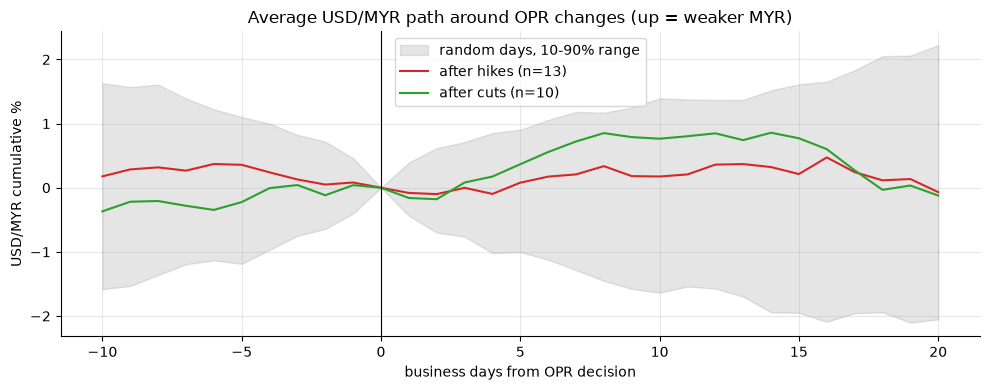

,events,mean % at +5d,mean % at +20d,random-day std at +20d
hikes,13,0.08,-0.07,1.79
cuts,10,0.37,-0.12,1.79


In [10]:
ch = ins.opr_changes(opr)
hikes, cuts = ch[ch["change_in_opr"] > 0], ch[ch["change_in_opr"] < 0]
ew_h = ins.event_window(w["USD"], hikes["date"])
ew_c = ins.event_window(w["USD"], cuts["date"])
rng = np.random.default_rng(0)
placebo = ins.event_window(w["USD"], pd.to_datetime(rng.choice(w.index[30:-30], 200, replace=False)))

fig, ax = plt.subplots(figsize=(10, 4))
band = placebo.quantile([0.1, 0.9], axis=1).T
ax.fill_between(band.index, band[0.1], band[0.9], color="gray", alpha=0.2,
                label="random days, 10-90% range")
ax.plot(ew_h.mean(axis=1), color="tab:red", label=f"after hikes (n={ew_h.shape[1]})")
ax.plot(ew_c.mean(axis=1), color="tab:green", label=f"after cuts (n={ew_c.shape[1]})")
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="business days from OPR decision", ylabel="USD/MYR cumulative %",
       title="Average USD/MYR path around OPR changes (up = weaker MYR)")
ax.legend(); plt.tight_layout(); plt.savefig(DOCS / "opr_event.png", dpi=120); plt.show()

pd.DataFrame({
    "events": [ew_h.shape[1], ew_c.shape[1]],
    "mean % at +5d": [ew_h.loc[5].mean(), ew_c.loc[5].mean()],
    "mean % at +20d": [ew_h.loc[20].mean(), ew_c.loc[20].mean()],
    "random-day std at +20d": [placebo.loc[20].std()] * 2,
}, index=["hikes", "cuts"]).round(2)

**Finding.** No detectable effect. Theory says a hike should strengthen MYR (USD/MYR down).
The average path after hikes and after cuts both stay well inside the range of ordinary random
days (20-day move ≈ −0.1%, against a random-day spread of about 1.8%). Two reasons. BNM moves in small 25 bp
steps that markets usually anticipate, so the news is priced in *before* the meeting. And
over 2006–2026 the OPR only ranged from 1.75% to 3.5%, which is small next to the swings in US
rates. With 13 hikes and 10 cuts the test is also low-powered. So "no detectable effect",
not "no effect".

## 7. Is there a best weekday to convert?

In [11]:
ins.weekday_effect(w["USD"]).round(3)

,mean_%,std_%,n,t_stat
date,,,,
Monday,0.002,0.460,987,0.116
Tuesday,0.033,0.361,1028,2.932
Wednesday,0.012,0.380,1041,0.999
Thursday,-0.024,0.421,1037,-1.866
Friday,-0.010,0.407,1038,-0.804


**Finding.** Only Tuesday shows a borderline effect (t ≈ 2.9; with 5 weekdays tested a
Bonferroni-adjusted threshold is about 2.6). Its size is **0.03% a day, about RM0.33 on a
RM1,000 transfer**, smaller than any bank's spread. Weekday timing is not worth acting on. This
is why the dashboard's "best day to convert" helper makes no prediction. It only shows where
today's rate sits in its 90-day range and suggests splitting large payments.

## 8. Can we forecast it? (summary; full method in `src/myr_fx/forecast.py`)
Walk-forward backtest: 24 non-overlapping monthly folds ending at today, 21 business days
(≈30 calendar days) ahead, each model refit on the 3 years before each fold.


USD/MYR
            MAE  MAPE_%  MAPE_day21_%  coverage95_%  MAE_vs_naive  t_vs_naive
model                                                                        
naive    0.0351  0.8374        1.2105       96.2302        1.0000      0.0000
arima    0.0355  0.8477        1.2598       98.2143        1.0112      0.3502
sarima   0.0355  0.8461        1.2131       97.4206        1.0121      0.4442
prophet  0.0765  1.8119        2.4414       59.3254        2.1809      4.0730

SGD/MYR
            MAE  MAPE_%  MAPE_day21_%  coverage95_%  MAE_vs_naive  t_vs_naive
model                                                                        
arima    0.0199  0.6169        0.8816       97.8175        0.9970     -0.0902
naive    0.0200  0.6191        0.8462       98.4127        1.0000      0.0000
sarima   0.0201  0.6219        0.8454       98.2143        1.0047      0.4567
prophet  0.0324  1.0082        1.3150       59.1270        1.6260      3.0544


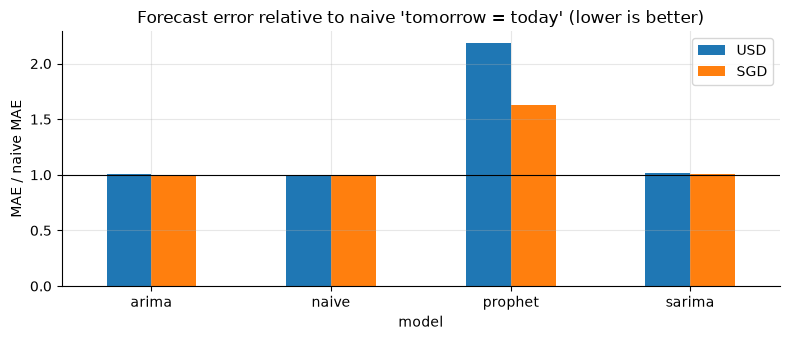

In [12]:
from myr_fx.forecast import score
tables = {p: score(pd.read_csv(ROOT / "reports" / f"backtest_{p.lower()}.csv",
                               parse_dates=["origin", "date"])) for p in ("USD", "SGD")}
for p, t in tables.items():
    print(f"\n{p}/MYR"); print(t.round(4).to_string())

fig, ax = plt.subplots(figsize=(8, 3.5))
pd.DataFrame({p: t["MAE_vs_naive"] for p, t in tables.items()}).plot.bar(ax=ax)
ax.axhline(1, color="k", lw=0.8)
ax.set_title("Forecast error relative to naive 'tomorrow = today' (lower is better)")
ax.set_ylabel("MAE / naive MAE"); plt.xticks(rotation=0)
plt.tight_layout(); plt.savefig(DOCS / "backtest.png", dpi=120); plt.show()

**Finding. The naive random walk wins.** ARIMA and SARIMA match it to within ±1.2% of MAE
(paired t-stats of 0.35 and 0.44 on USD, −0.09 and 0.46 on SGD, all well inside noise).
Auto-ARIMA mostly picks a random walk on its own, and the weekly SARIMA term adds nothing.
**Prophet is about 2x worse**, and its 95% band contains the actual rate only **59%** of the time.
It extrapolates trend and yearly seasonality that FX simply doesn't have.

This is the textbook result (Meese and Rogoff, 1983). In a liquid FX market, anything predictable is
traded away, so the best point forecast of next month's rate is about today's rate. The useful
output is not the line but the **width of the band**: a typical 30-day error of about 1.2% (about
RM0.05 per USD) tells a student how much budget buffer to keep.

## Summary
1. **MYR's big moves are episodic:** 2014–16 oil and 1MDB (+36% USD/MYR), 2022–24 Fed hikes
   (+15%), then a 14% rebound in 2024. Basket strength peaked at GE13 (May 2013) and bottomed in
   Feb 2024.
2. **The US–Malaysia rate gap explains the *level* of USD/MYR (ρ = 0.49). Oil helps a little
   month to month.** Together they explain about 2% of monthly variation.
3. **OPR decisions have no detectable short-term effect.** They are anticipated, and they are small
   next to moves in US rates.
4. **USD and CNY move almost as one against MYR (ρ = 0.88). SGD is the calmest pair.**
5. **No model beats "tomorrow = today" for a 30-day horizon.** Prophet is significantly worse.
   Use the forecast band for budgeting, not the line for timing.